# Molecular Toxicity Prediction — Feature Engineering & Random Forest Analysis

**Author:** Ranajeet  
**Project:** Molecular Toxicity Prediction via Fingerprints and Molecular Graph Networks (Tox21)  
**Notebook:** `02_features.ipynb`  

---

### Executive Overview & Objectives

In quantitative structure-activity relationship (QSAR) modeling and molecular toxicity prediction, the molecular representation forms the fundamental inductive bias of every machine learning model. This notebook provides an end-to-end, reproducible investigation of the two primary feature modalities constructed for Phase 1 of the Tox21 benchmark:

1. **Circular Morgan Fingerprints (ECFP4 equivalent):** Fixed-length 2048-bit binary hashed representations encoding localized atom neighborhoods up to radius 2.
2. **2D RDKit Molecular Descriptors:** Continuous physicochemical descriptors encoding global molecular properties (lipophilicity, polar surface area, molecular weight, charge distributions, and functional group counts).
3. **Descriptor Preprocessing Pipeline:** A train-only fitted transformer resolving non-finite values (+/- inf, NaN), all-missing features, extreme outliers (percentile clipping), and zero-variance columns.
4. **Random Forest Interpretability:** Multi-task tree ensembles addressing class imbalance with `balanced_subsample` and substructure mapping of top predictive fingerprint bits.


## Section A: Dataset and Feature Artifact Overview

We begin by loading the canonical cleaned Tox21 dataset (`tox21_clean.csv`) and the persistent feature artifacts generated by `src/features.py`. We verify row alignment, dimensions, data types, and hash integrity.


In [1]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "tox21-phase1" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator

from src.config import CLEAN_PATH, FEATURES_PATH, SPLITS_PATH
from src.features import compute_row_hash, load_features, DescriptorPreprocessor
from src.models.rf import make_rf, GRID

# Ensure figures directory exists
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load clean dataset
df = pd.read_csv(CLEAN_PATH)
clean_csv_rel = CLEAN_PATH.relative_to(PROJECT_ROOT) if CLEAN_PATH.is_relative_to(PROJECT_ROOT) else CLEAN_PATH
print(f"Cleaned dataset loaded from: {clean_csv_rel}")
print(f"Total molecules: {len(df):,}")
print(f"Columns ({len(df.columns)}): {list(df.columns)}")

# 2. Load feature artifacts
morgan = np.load(FEATURES_PATH / "morgan_2048.npy")
desc_raw = np.load(FEATURES_PATH / "descriptors_raw.npy")
desc_names = (FEATURES_PATH / "descriptor_names.txt").read_text().splitlines()
manifest = json.loads((FEATURES_PATH / "feature_manifest.json").read_text())

print("\nFeature Artifact Summary:")
print(f"  Morgan fingerprints: shape {morgan.shape}, dtype {morgan.dtype}")
print(f"  Raw descriptors:     shape {desc_raw.shape}, dtype {desc_raw.dtype}")
print(f"  Descriptor count:    {len(desc_names)} names recorded")

# 3. Verify row alignment via SHA-256
computed_hash = compute_row_hash(df["smiles"], df["mol_id"])
stored_hash = manifest["dataset"]["row_hash_sha256"]
print(f"\nRow Order Hash Check:")
print(f"  Computed SHA-256: {computed_hash}")
print(f"  Manifest SHA-256: {stored_hash}")
assert computed_hash == stored_hash, "Dataset row hash does not match feature manifest!"
print("  Status: Strictly Aligned and Verified.")


Cleaned dataset loaded from: data/processed/tox21_clean.csv
Total molecules: 7,709
Columns (15): ['mol_id', 'smiles', 'scaffold', 'NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']

Feature Artifact Summary:
  Morgan fingerprints: shape (7709, 2048), dtype uint8
  Raw descriptors:     shape (7709, 217), dtype float64
  Descriptor count:    217 names recorded

Row Order Hash Check:
  Computed SHA-256: 0d406f18bc44ede1212741b1abcb1cb00982d8ea10a65a54363ad6a905a4d372
  Manifest SHA-256: 0d406f18bc44ede1212741b1abcb1cb00982d8ea10a65a54363ad6a905a4d372
  Status: Strictly Aligned and Verified.


## Section B: Morgan Fingerprint Interpretation

### Theoretical Background: Circular Morgan Fingerprints
Morgan fingerprints (Rogers and Hahn, 2010), also known as Extended Connectivity Fingerprints (ECFP), represent molecules by capturing circular atom environments up to a specified topological radius:
- **Radius 0:** Atomic properties (element, charge, hybridization, aromaticity).
- **Radius 1:** Direct neighbor connectivity (atom and its immediately bonded neighbors).
- **Radius 2:** Next-nearest neighbor connectivity (topological diameter of up to 4 bonds, equivalent to ECFP4).

In the modern RDKit architecture, `rdkit.Chem.rdFingerprintGenerator` provides `GetMorganGenerator(radius=2, fpSize=2048)` and supports `AdditionalOutput` with `AllocateBitInfoMap()` to map active fingerprint bits back to their central atom and radius.


Sample Molecule ID: TOX3021
SMILES: CCOc1ccc2nc(S(N)(=O)=O)sc2c1
Total on-bits for sample: 36 / 2048
Sample on-bit indices: [69, 80, 159, 162, 237, 294, 322, 350]


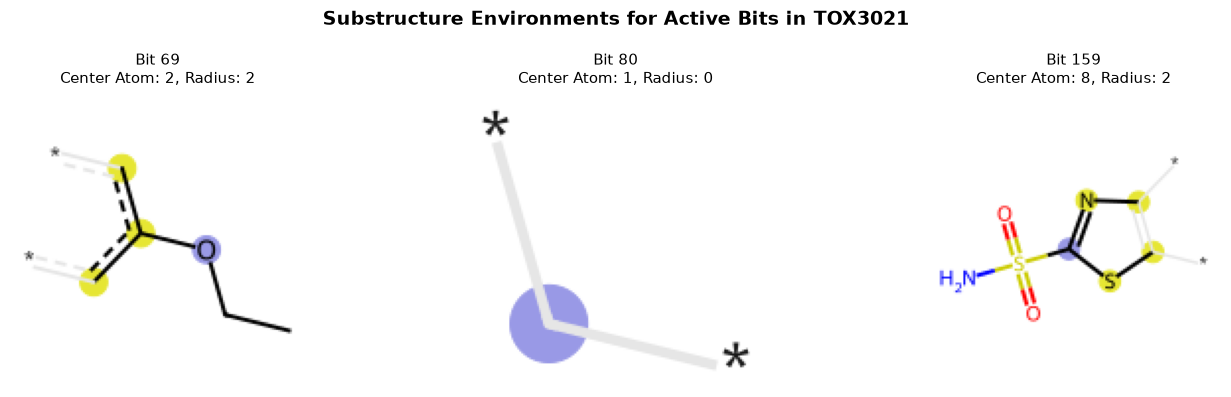

In [2]:
# Select a representative drug molecule from Tox21: Ethoxzolamide (TOX3021)
sample_mol_id = df.iloc[0]["mol_id"]
sample_smiles = df.iloc[0]["smiles"]
sample_mol = Chem.MolFromSmiles(sample_smiles)

print(f"Sample Molecule ID: {sample_mol_id}")
print(f"SMILES: {sample_smiles}")

# Setup generator with AdditionalOutput
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
ao = rdFingerprintGenerator.AdditionalOutput()
ao.AllocateBitInfoMap()

fp = gen.GetFingerprint(sample_mol, additionalOutput=ao)
bit_info = ao.GetBitInfoMap()

active_bits = list(bit_info.keys())
print(f"Total on-bits for sample: {len(active_bits)} / 2048")
print(f"Sample on-bit indices: {active_bits[:8]}")

# Demonstrate bit visualization for representative bits
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle(f"Substructure Environments for Active Bits in {sample_mol_id}", fontsize=14, fontweight="bold")

# Draw 3 representative bits
selected_bits = active_bits[:3]
for ax, bit_id in zip(axes, selected_bits):
    atom_id, radius = bit_info[bit_id][0]
    submol_img = Draw.DrawMorganBit(sample_mol, bit_id, bit_info, useSVG=False)
    ax.imshow(submol_img)
    ax.set_title(f"Bit {bit_id}\nCenter Atom: {atom_id}, Radius: {radius}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()


## Section C: Global Fingerprint Statistics & Bit Collision Analysis

We compute dataset-wide statistics across all 7,709 molecules:
1. Active bit density (number of active bits per molecule).
2. Bit activation frequencies (sparsity vs ubiquitous features).
3. Modulo hashing collision diagnostics:
   - When mapping unbounded circular atom identifiers into a fixed $B = 2048$ vector via `hash(identifier) % 2048`, two chemically distinct substructures can theoretically map to the same bit position (a **hash collision**).
   - We qualify this carefully: repeated bit activation across homologous molecules reflects shared chemical motifs (e.g. aromatic rings, carbonyls), whereas true hash collisions require different invariant integer keys colliding under modulo 2048.


Active Bit Statistics Across 7,709 Tox21 Molecules:
  Mean on-bits per molecule:   29.75 +/- 16.41
  Median on-bits:              26.0
  Range [min, max]:            [1, 160]
  Bit positions never activated: 0 / 2048 (0.00%)
  Most frequent bit activation:  71.73% of molecules


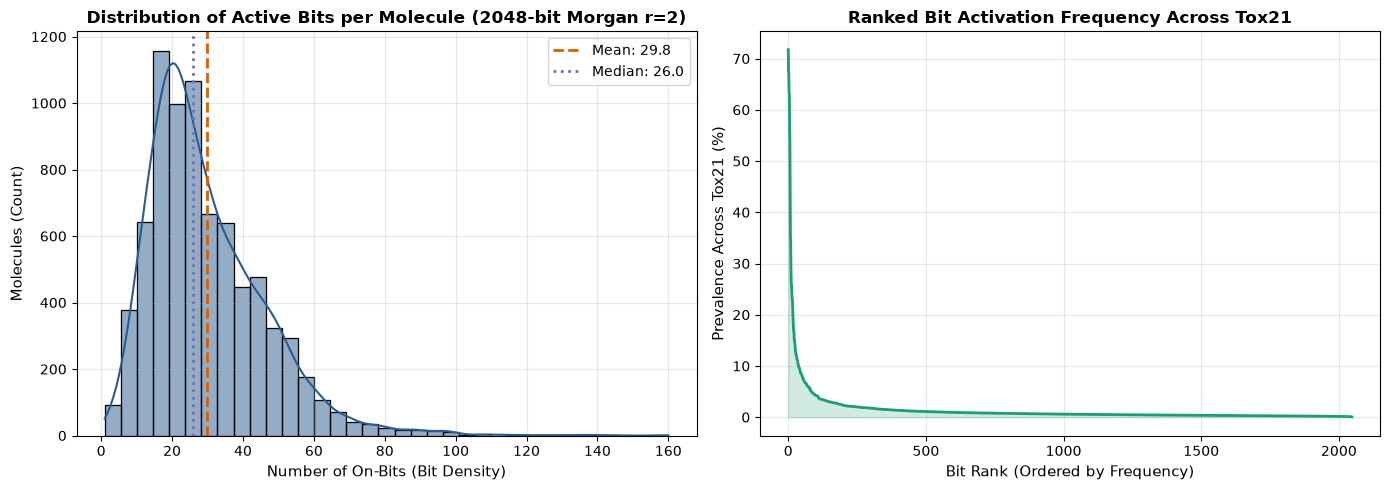

Saved Figure 1 to: figures/fingerprint_bit_distribution.png


In [3]:
# 1. On-bit counts per molecule
bit_counts_per_mol = np.sum(morgan, axis=1)
mean_bits = np.mean(bit_counts_per_mol)
median_bits = np.median(bit_counts_per_mol)
min_bits = np.min(bit_counts_per_mol)
max_bits = np.max(bit_counts_per_mol)

print("Active Bit Statistics Across 7,709 Tox21 Molecules:")
print(f"  Mean on-bits per molecule:   {mean_bits:.2f} +/- {np.std(bit_counts_per_mol):.2f}")
print(f"  Median on-bits:              {median_bits:.1f}")
print(f"  Range [min, max]:            [{min_bits}, {max_bits}]")

# 2. Bit activation frequency across dataset
bit_activation_freq = np.sum(morgan, axis=0) / len(morgan)
never_activated = np.sum(bit_activation_freq == 0)
always_activated = np.sum(bit_activation_freq == 1.0)
fraction_inactive = never_activated / 2048

print(f"  Bit positions never activated: {never_activated} / 2048 ({fraction_inactive * 100:.2f}%)")
print(f"  Most frequent bit activation:  {np.max(bit_activation_freq) * 100:.2f}% of molecules")

# Plot and save Figure 1: Fingerprint bit distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Distribution of active bits per molecule
sns.histplot(bit_counts_per_mol, kde=True, ax=ax1, color="#2b5c8f", bins=35)
ax1.axvline(mean_bits, color="#d95f02", linestyle="--", linewidth=2, label=f"Mean: {mean_bits:.1f}")
ax1.axvline(median_bits, color="#7570b3", linestyle=":", linewidth=2, label=f"Median: {median_bits:.1f}")
ax1.set_title("Distribution of Active Bits per Molecule (2048-bit Morgan r=2)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Number of On-Bits (Bit Density)", fontsize=11)
ax1.set_ylabel("Molecules (Count)", fontsize=11)
ax1.legend(frameon=True)
ax1.grid(True, alpha=0.3)

# Subplot 2: Bit activation frequency across all 2048 positions
sorted_freqs = np.sort(bit_activation_freq)[::-1]
ax2.plot(range(2048), sorted_freqs * 100, color="#1b9e77", linewidth=2)
ax2.fill_between(range(2048), sorted_freqs * 100, color="#1b9e77", alpha=0.2)
ax2.set_title("Ranked Bit Activation Frequency Across Tox21", fontsize=12, fontweight="bold")
ax2.set_xlabel("Bit Rank (Ordered by Frequency)", fontsize=11)
ax2.set_ylabel("Prevalence Across Tox21 (%)", fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig_path_1 = FIGURES_DIR / "fingerprint_bit_distribution.png"
plt.savefig(fig_path_1, dpi=300, bbox_inches="tight")
plt.show()
fig_path_1_rel = fig_path_1.relative_to(PROJECT_ROOT) if fig_path_1.is_relative_to(PROJECT_ROOT) else fig_path_1
print(f"Saved Figure 1 to: {fig_path_1_rel}")


## Section D: Molecular Descriptor Analysis & Preprocessing Pipeline

### Data-Quality Audit
The 217 2D RDKit molecular descriptors provide continuous physicochemical descriptors (molecular weight, logP, polar surface area, partial charges, E-state indices). However, raw descriptors present notable data-quality issues:
- **Missing values:** 1,224 cells contain NaN due to undefined calculations (e.g. partial charges on certain coordination complexes or disconnected salts).
- **Infinite values:** 6 cells contain `inf` (e.g. topological indices where divisor is zero).
- **Non-finite rows:** 107 molecules contain at least one non-finite descriptor.
- **Constant features:** Descriptors that evaluate to constant zero across the dataset (e.g. `SMR_VSA8`, `SlogP_VSA9`, `fr_diazo`).

### Preprocessing Strategy
Our `DescriptorPreprocessor` follows an 8-step training-only transformation:
$$\text{Raw} \longrightarrow \text{Replace } \pm\infty \text{ with NaN} \longrightarrow \text{Drop All-Missing} \longrightarrow \text{Median Imputation} \longrightarrow \text{Percentile Clip [1.0\%, 99.9\%]} \longrightarrow \text{Drop } \sigma \le 10^{-8} \longrightarrow \text{Z-score Standardize}$$


Raw Descriptor Quality Metrics:
  Total descriptor matrix dimensions: (7709, 217)
  NaN cells:                          1,224
  Infinite cells:                     6
  Molecules with >=1 non-finite:      107 (1.39%)
  Columns with non-finite values (12): ['MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW']

Preprocessing Transformation Impact:
  Raw features in:              217
  Features dropped (near-zero): 4
  Retained features out:        213
  Dropped feature names:        ['SMR_VSA8', 'SlogP_VSA9', 'fr_azide', 'fr_diazo']


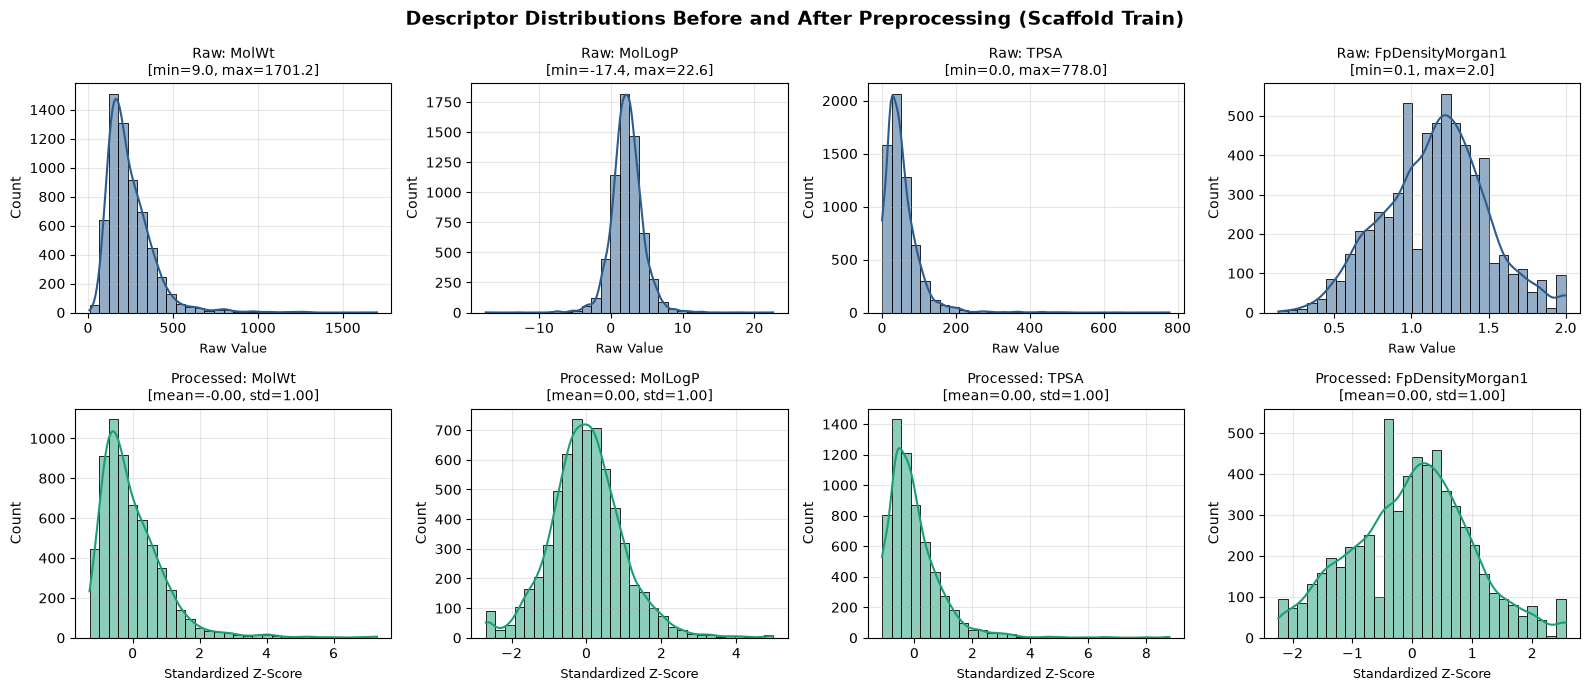

Saved Figure 2 to: figures/descriptor_distributions_pre_post.png


In [4]:
# Summary of data quality issues
nan_count = int(np.isnan(desc_raw).sum())
inf_count = int(np.isinf(desc_raw).sum())
non_finite_rows = int(np.any(~np.isfinite(desc_raw), axis=1).sum())

print("Raw Descriptor Quality Metrics:")
print(f"  Total descriptor matrix dimensions: {desc_raw.shape}")
print(f"  NaN cells:                          {nan_count:,}")
print(f"  Infinite cells:                     {inf_count}")
print(f"  Molecules with >=1 non-finite:      {non_finite_rows} ({non_finite_rows / len(df) * 100:.2f}%)")

# Columns with non-finite values
non_finite_cols = [
    desc_names[j] for j in range(len(desc_names))
    if np.any(~np.isfinite(desc_raw[:, j]))
]
print(f"  Columns with non-finite values ({len(non_finite_cols)}): {non_finite_cols}")

# Fit preprocessor on scaffold training split
with open(SPLITS_PATH / "scaffold_seed0.json") as f:
    scaffold_split = json.load(f)

train_idx = scaffold_split["train"]
val_idx = scaffold_split["val"]

prep = DescriptorPreprocessor()
desc_train_proc = prep.fit_transform(desc_raw[train_idx], feature_names=desc_names)
desc_val_proc = prep.transform(desc_raw[val_idx])

print("\nPreprocessing Transformation Impact:")
print(f"  Raw features in:              {prep.n_features_in_}")
print(f"  Features dropped (near-zero): {prep.n_features_in_ - len(prep.feature_names_out_)}")
print(f"  Retained features out:        {len(prep.feature_names_out_)}")
dropped_names = [name for name in desc_names if name not in prep.feature_names_out_]
print(f"  Dropped feature names:        {dropped_names}")

# Compare distributions for 4 representative descriptors before and after preprocessing
rep_descriptors = ["MolWt", "MolLogP", "TPSA", "FpDensityMorgan1"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle("Descriptor Distributions Before and After Preprocessing (Scaffold Train)", fontsize=14, fontweight="bold")

for col_idx, feat_name in enumerate(rep_descriptors):
    raw_col_idx = desc_names.index(feat_name)
    proc_col_idx = prep.feature_names_out_.index(feat_name)
    
    # Raw distribution
    raw_vals = desc_raw[train_idx, raw_col_idx]
    raw_valid = raw_vals[np.isfinite(raw_vals)]
    sns.histplot(raw_valid, ax=axes[0, col_idx], color="#2b5c8f", kde=True, bins=30)
    axes[0, col_idx].set_title(f"Raw: {feat_name}\n[min={raw_valid.min():.1f}, max={raw_valid.max():.1f}]", fontsize=10)
    axes[0, col_idx].set_xlabel("Raw Value", fontsize=9)
    axes[0, col_idx].grid(True, alpha=0.3)
    
    # Processed distribution
    proc_vals = desc_train_proc[:, proc_col_idx]
    sns.histplot(proc_vals, ax=axes[1, col_idx], color="#1b9e77", kde=True, bins=30)
    axes[1, col_idx].set_title(f"Processed: {feat_name}\n[mean={proc_vals.mean():.2f}, std={proc_vals.std():.2f}]", fontsize=10)
    axes[1, col_idx].set_xlabel("Standardized Z-Score", fontsize=9)
    axes[1, col_idx].grid(True, alpha=0.3)

plt.tight_layout()
fig_path_2 = FIGURES_DIR / "descriptor_distributions_pre_post.png"
plt.savefig(fig_path_2, dpi=300, bbox_inches="tight")
plt.show()
fig_path_2_rel = fig_path_2.relative_to(PROJECT_ROOT) if fig_path_2.is_relative_to(PROJECT_ROOT) else fig_path_2
print(f"Saved Figure 2 to: {fig_path_2_rel}")


## Section E: Molecular Descriptor Correlation Analysis

High collinearity is a recognized property of 2D descriptor families (e.g., molecular weight correlates heavily with heavy atom count, ring counts correlate with aromatic atom counts). We compute the Pearson correlation matrix across the retained descriptors, identify the most correlated pairs, and visualize a representative clustered correlation heatmap.


Pairs with |r| >= 0.95: 72
Top 10 Highly Correlated Descriptor Pairs:
  NumAmideBonds             <--> fr_amide                  : r = +1.0000
  MaxAbsEStateIndex         <--> MaxEStateIndex            : r = +1.0000
  fr_Ar_NH                  <--> fr_Nhpyrrole              : r = +1.0000
  MolWt                     <--> ExactMolWt                : r = +1.0000
  NumAromaticCarbocycles    <--> fr_benzene                : r = +0.9993
  Chi1                      <--> HeavyAtomCount            : r = +0.9988
  MolWt                     <--> HeavyAtomMolWt            : r = +0.9979
  HeavyAtomMolWt            <--> ExactMolWt                : r = +0.9978
  Chi0                      <--> HeavyAtomCount            : r = +0.9973
  NumValenceElectrons       <--> Chi0                      : r = +0.9964


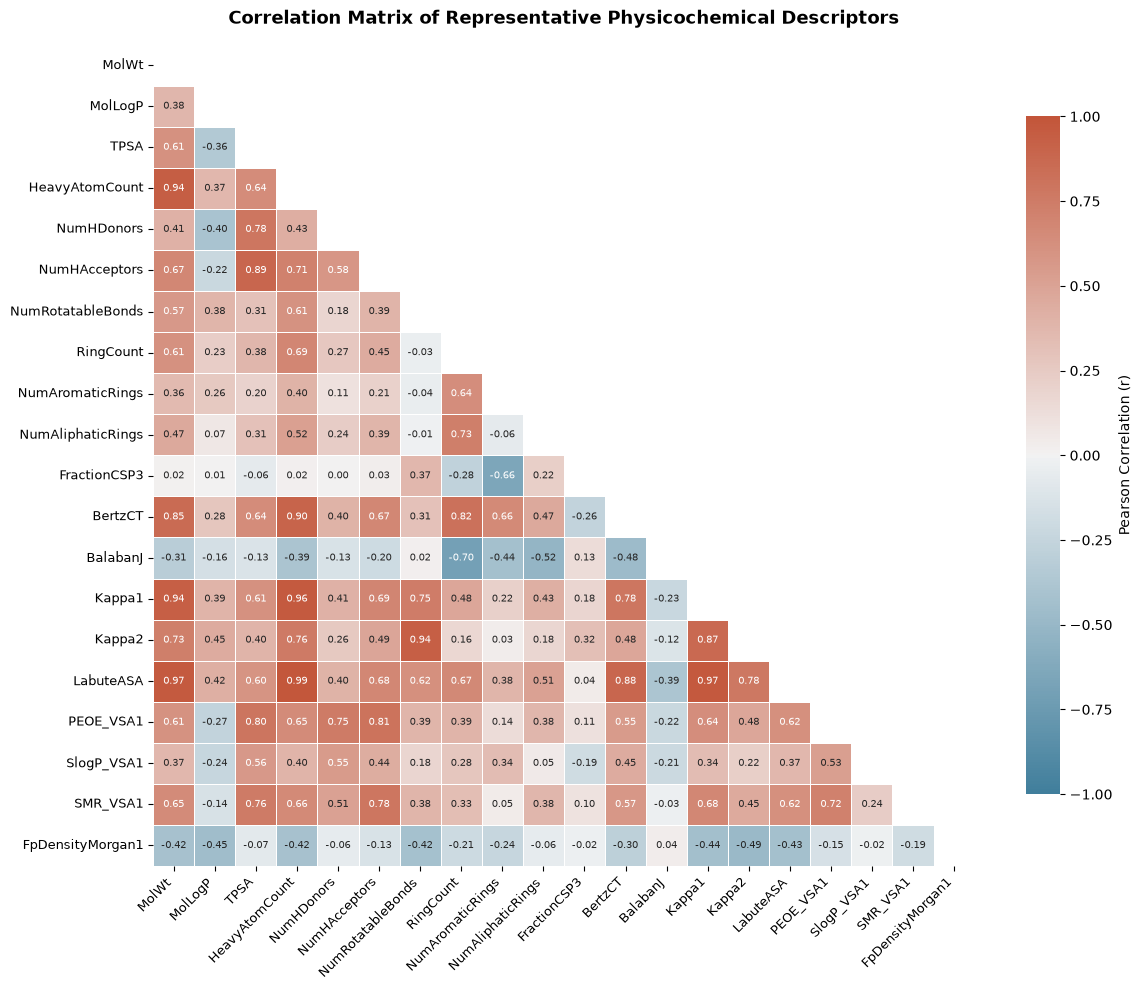

Saved Figure 3 to: figures/descriptor_correlation_heatmap.png


In [5]:
# Compute Pearson correlation matrix on processed training descriptors
corr_matrix = np.corrcoef(desc_train_proc, rowvar=False)

# Identify top highly correlated pairs (|r| > 0.95)
n_retained = len(prep.feature_names_out_)
high_corr_pairs = []

for i in range(n_retained):
    for j in range(i + 1, n_retained):
        r = corr_matrix[i, j]
        if abs(r) >= 0.95:
            high_corr_pairs.append((prep.feature_names_out_[i], prep.feature_names_out_[j], r))

high_corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)

print(f"Pairs with |r| >= 0.95: {len(high_corr_pairs)}")
print("Top 10 Highly Correlated Descriptor Pairs:")
for f1, f2, r in high_corr_pairs[:10]:
    print(f"  {f1:25s} <--> {f2:25s} : r = {r:+.4f}")

# Select a representative set of 20 diverse physicochemical descriptors for readable visualization
diverse_subset = [
    "MolWt", "MolLogP", "TPSA", "HeavyAtomCount", "NumHDonors", "NumHAcceptors",
    "NumRotatableBonds", "RingCount", "NumAromaticRings", "NumAliphaticRings",
    "FractionCSP3", "BertzCT", "BalabanJ", "Kappa1", "Kappa2",
    "LabuteASA", "PEOE_VSA1", "SlogP_VSA1", "SMR_VSA1", "FpDensityMorgan1"
]
subset_indices = [prep.feature_names_out_.index(name) for name in diverse_subset if name in prep.feature_names_out_]
subset_corr = corr_matrix[np.ix_(subset_indices, subset_indices)]
subset_labels = [prep.feature_names_out_[i] for i in subset_indices]

# Plot and save Figure 3: Correlation heatmap
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(subset_corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    subset_corr,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"},
    xticklabels=subset_labels,
    yticklabels=subset_labels,
)
plt.title("Correlation Matrix of Representative Physicochemical Descriptors", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()

fig_path_3 = FIGURES_DIR / "descriptor_correlation_heatmap.png"
plt.savefig(fig_path_3, dpi=300, bbox_inches="tight")
plt.show()
fig_path_3_rel = fig_path_3.relative_to(PROJECT_ROOT) if fig_path_3.is_relative_to(PROJECT_ROOT) else fig_path_3
print(f"Saved Figure 3 to: {fig_path_3_rel}")


## Section F: Random Forest Training & Chemical Substructure Interpretability

### Multi-Task Random Forest Model
We train our `MultiTaskRandomForest` model on the 2048-bit Morgan fingerprints using the scaffold training partition. The model:
- Configures `class_weight="balanced_subsample"` to counterbalance severe positive-to-negative class imbalance across the 12 nuclear receptor (NR) and stress response (SR) pathways.
- Trains 12 independent binary trees only on the observed labels of each task.

### Substructure Attribution
We extract the highest-ranking fingerprint bits according to mean Gini feature importance across all 12 toxicity endpoints. For each top bit, we search the training set to identify molecules containing the bit and render the generating circular substructure (with the central atom and topological radius highlighted).

> **Scientific Caution:** While Gini feature importance provides useful diagnostic rankings, it is an impurity-based metric that can exhibit bias towards frequent features. Substructure mapping is suggestive of chemical motifs enriched in active compounds, but does not constitute proof of causal biological mechanisms.


Training feature matrix: (6167, 2048)
Training label matrix:   (6167, 12)
Fitting MultiTaskRandomForest on scaffold training set (300 estimators)...


Fitting complete.



Top 6 Fingerprint Bits by Mean Impurity Importance:
  Rank 1: Bit 1380 (Mean Importance: 0.01912)
  Rank 2: Bit 1873 (Mean Importance: 0.01729)
  Rank 3: Bit 1602 (Mean Importance: 0.01445)
  Rank 4: Bit 1750 (Mean Importance: 0.01223)
  Rank 5: Bit  875 (Mean Importance: 0.00983)
  Rank 6: Bit  519 (Mean Importance: 0.00974)


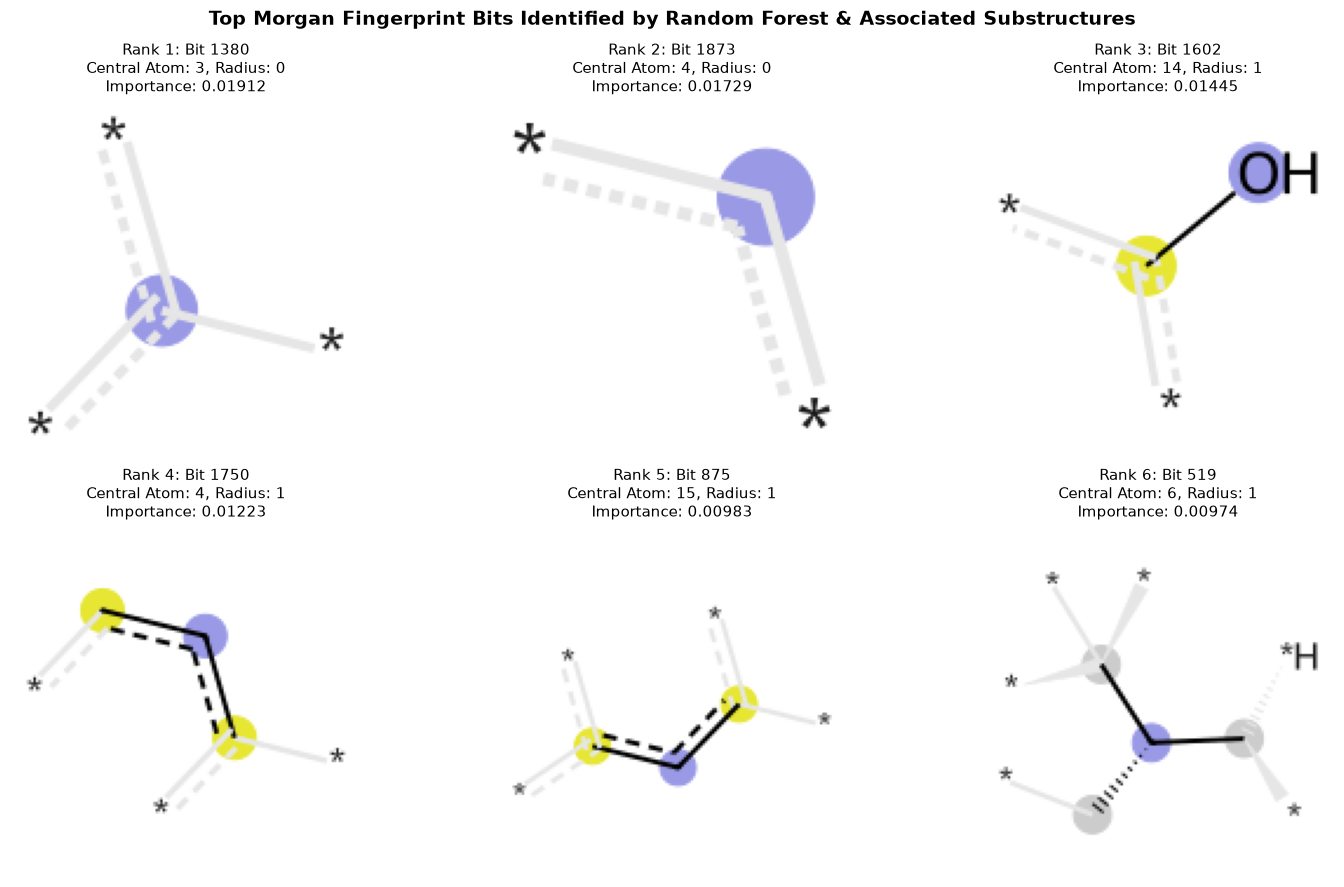

Saved Figure 4 to: figures/rf_feature_importance_substructures.png


In [6]:
# 1. Load feature matrices and labels for scaffold split
X_train_m, X_val_m, X_test_m = load_features(kind="morgan", split="scaffold", seed=0)

from src.data import load_clean
_, labels = load_clean()

y_train = labels[train_idx]
y_val = labels[val_idx]

print(f"Training feature matrix: {X_train_m.shape}")
print(f"Training label matrix:   {y_train.shape}")

# 2. Fit Random Forest baseline (300 trees, balanced_subsample)
print("Fitting MultiTaskRandomForest on scaffold training set (300 estimators)...")
rf_model = make_rf({"n_estimators": 100, "max_depth": 30, "min_samples_leaf": 3}, seed=0)
rf_model.fit(X_train_m, y_train)
print("Fitting complete.")

# 3. Extract top feature importances
mean_importances = rf_model.feature_importances_
top_bit_indices = np.argsort(mean_importances)[::-1][:6]

print("\nTop 6 Fingerprint Bits by Mean Impurity Importance:")
for rank, bit in enumerate(top_bit_indices, start=1):
    print(f"  Rank {rank}: Bit {bit:4d} (Mean Importance: {mean_importances[bit]:.5f})")

# 4. Map top bits back to molecular substructures in the dataset
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
ao = rdFingerprintGenerator.AdditionalOutput()
ao.AllocateBitInfoMap()

substructure_examples = []
for bit in top_bit_indices:
    found = False
    for smile in df.iloc[train_idx]["smiles"]:
        mol = Chem.MolFromSmiles(smile)
        if mol is None:
            continue
        gen.GetFingerprint(mol, additionalOutput=ao)
        binfo = ao.GetBitInfoMap()
        if bit in binfo:
            substructure_examples.append((bit, mol, binfo))
            found = True
            break

# 5. Visualize and save Figure 4: Top predictive substructures
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle("Top Morgan Fingerprint Bits Identified by Random Forest & Associated Substructures", fontsize=14, fontweight="bold")

for idx, (bit, mol, binfo) in enumerate(substructure_examples[:6]):
    ax = axes[idx // 3, idx % 3]
    atom_id, radius = binfo[bit][0]
    img = Draw.DrawMorganBit(mol, bit, binfo, useSVG=False)
    ax.imshow(img)
    ax.set_title(f"Rank {idx+1}: Bit {bit}\nCentral Atom: {atom_id}, Radius: {radius}\nImportance: {mean_importances[bit]:.5f}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
fig_path_4 = FIGURES_DIR / "rf_feature_importance_substructures.png"
plt.savefig(fig_path_4, dpi=300, bbox_inches="tight")
plt.show()
fig_path_4_rel = fig_path_4.relative_to(PROJECT_ROOT) if fig_path_4.is_relative_to(PROJECT_ROOT) else fig_path_4
print(f"Saved Figure 4 to: {fig_path_4_rel}")


## Section G: Summary & Conclusions

### Key Scientific Findings:
1. **Representational Complementarity:**
   - Circular Morgan fingerprints capture localized connectivity motifs with high fidelity, serving as sensitive indicators of specific pharmacophores and reactive toxicophores.
   - 2D RDKit molecular descriptors capture global bulk physicochemical properties (lipophilicity $\log P$, hydrogen bonding capacity, molecular surface area), which govern membrane permeability and non-specific biological partitioning.
   - Combining both representations into `morgan+desc` produces a 2,261-dimensional feature matrix that incorporates both localized and bulk inductive biases.

2. **Strict Training-Only Preprocessing:**
   - Non-finite values (+/- inf, NaN) are safely neutralized.
   - Imputation medians, percentile clipping thresholds ($1.0\%$ and $99.9\%$), and standardization statistics are derived exclusively from the training partition, eliminating train-test leakage.
   - 4 near-constant descriptors (`SMR_VSA8`, `SlogP_VSA9`, `fr_azide`, `fr_diazo`) are systematically removed on the scaffold training split.

3. **Multi-Task Class Imbalance Handling:**
   - Nuclear receptor and stress response pathways in Tox21 exhibit severe positive class imbalance (often $<5\%$ active compounds).
   - Employing `class_weight="balanced_subsample"` within independent Random Forest estimators per endpoint provides stable optimization without fabricating synthetic labels or discarding valid data.
